# 01 - Veri keşfi

WeedsGalore veri setini indirip yapısına, bant değerlerine, sınıf dağılımına ve nesne boyutlarına bakıyorum. Ön işleme ve deney kararlarının dayanağı bu notebook.

## 1. Kurulum ve veri

In [ ]:
# Google Drive'ı bağla: kalıcı dosyalar (veri zip'i, modeller, sonuçlar) burada durur
from google.colab import drive
drive.mount('/content/drive')

import os, glob, random, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Proje yolları (Drive üzerinde)
ROOT     = '/content/drive/MyDrive/multispectral-weed-segmentation'
DATA_DIR = f'{ROOT}/data'          # veri zip'i
CKPT_DIR = f'{ROOT}/checkpoints'   # eğitilmiş modeller
RES_DIR  = f'{ROOT}/results'       # tablolar ve grafikler
for d in [DATA_DIR, CKPT_DIR, RES_DIR]:
    os.makedirs(d, exist_ok=True)

# Veriyi Drive'a sadece bir kez indir (~321 MB)
URL      = 'https://doidata.gfz.de/weedsgalore_e_celikkan_2024/weedsgalore-dataset.zip'
ZIP_PATH = f'{DATA_DIR}/weedsgalore-dataset.zip'
if not os.path.exists(ZIP_PATH):
    print('İndiriliyor... (birkaç dakika sürebilir)')
    urllib.request.urlretrieve(URL, ZIP_PATH + '.part')
    os.rename(ZIP_PATH + '.part', ZIP_PATH)
print(f'Zip boyutu: {os.path.getsize(ZIP_PATH)/1e6:.0f} MB')

# Her oturumda zip'i hızlı yerel diske (/content) aç
LOCAL = '/content/data'
if not os.path.exists(LOCAL):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL)

DATASET = os.path.dirname(glob.glob(f'{LOCAL}/**/2023-05-25', recursive=True)[0])
print('Veri kökü:', DATASET)

# Tekrarlanabilirlik: rastgelelik tohumunu sabitle
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Hızlı kontrol: her klasörün alt klasörleri ve dosya sayıları
for name in sorted(os.listdir(DATASET)):
    p = os.path.join(DATASET, name)
    if os.path.isdir(p):
        alt = {s: len(os.listdir(os.path.join(p, s)))
               for s in sorted(os.listdir(p)) if os.path.isdir(os.path.join(p, s))}
        print(f'{name:12s}', alt if alt else sorted(os.listdir(p)))

Zip boyutu: 337 MB
Veri kökü: /content/data/weedsgalore-dataset
2023-05-25   {'images': 240, 'instances': 48, 'logs': 0, 'semantics': 49}
2023-05-30   {'images': 240, 'instances': 48, 'logs': 0, 'semantics': 48}
2023-06-06   {'images': 240, 'instances': 48, 'logs': 0, 'semantics': 48}
2023-06-15   {'images': 60, 'instances': 12, 'logs': 0, 'semantics': 12}
splits       ['test.txt', 'train.txt', 'val.txt']


## 2. Split ve dosya kontrolü

In [ ]:
import collections
DATES = ['2023-05-25', '2023-05-30', '2023-06-06', '2023-06-15']
BANDS = ['B', 'G', 'R', 'RE', 'NIR']   # Mavi, Yeşil, Kırmızı, RedEdge, Yakın kızılötesi

# Split listelerini oku: her satır bir görüntü adı, ör. "2023-06-15_0472"
splits = {}
for s in ['train', 'val', 'test']:
    with open(f'{DATASET}/splits/{s}.txt') as f:
        splits[s] = [satir.strip() for satir in f if satir.strip()]
    tarih_say = collections.Counter(ad[:10] for ad in splits[s])
    print(f'{s:5s}: {len(splits[s]):3d} görüntü | tarih başına: {dict(sorted(tarih_say.items()))}')

# Sızıntı kontrolü: aynı görüntü iki split'te birden olmamalı
tum = splits['train'] + splits['val'] + splits['test']
print('Toplam:', len(tum), '| birden fazla split\'te geçen ad:', len(tum) - len(set(tum)))

# semantics klasöründe karşılığı olmayan (fazla) dosya var mı?
for d in DATES:
    maskeler   = sorted(os.listdir(f'{DATASET}/{d}/semantics'))
    goruntuler = {f.rsplit('_', 1)[0] for f in os.listdir(f'{DATASET}/{d}/images')}
    fazla = [m for m in maskeler if m.replace('.png', '') not in goruntuler]
    if fazla:
        print(f'{d} fazla dosya:', fazla)

# Split'teki her görüntünün 5 bandı ve maskesi diskte var mı?
eksik = [ad for ad in tum
         if not all(os.path.exists(f'{DATASET}/{ad[:10]}/images/{ad}_{b}.png') for b in BANDS)
         or not os.path.exists(f'{DATASET}/{ad[:10]}/semantics/{ad}.png')]
print('Eksik dosyası olan görüntü sayısı:', len(eksik))

# Tek bir örnek görüntünün formatı: boyut, veri tipi, değer aralığı
ornek = splits['train'][0]
print('\nÖrnek:', ornek)
for b in BANDS:
    a = np.array(Image.open(f'{DATASET}/{ornek[:10]}/images/{ornek}_{b}.png'))
    print(f'  {b:3s} shape={a.shape} dtype={a.dtype} min={a.min()} max={a.max()}')
m = np.array(Image.open(f'{DATASET}/{ornek[:10]}/semantics/{ornek}.png'))
print(f'  maske shape={m.shape} dtype={m.dtype} sınıf değerleri={np.unique(m)}')

train: 104 görüntü | tarih başına: {'2023-05-25': 32, '2023-05-30': 32, '2023-06-06': 32, '2023-06-15': 8}
val  :  26 görüntü | tarih başına: {'2023-05-25': 8, '2023-05-30': 8, '2023-06-06': 8, '2023-06-15': 2}
test :  26 görüntü | tarih başına: {'2023-05-25': 8, '2023-05-30': 8, '2023-06-06': 8, '2023-06-15': 2}
Toplam: 156 | birden fazla split'te geçen ad: 0
2023-05-25 fazla dosya: ['2023-05-25_0750.png.aux.xml']
Eksik dosyası olan görüntü sayısı: 0

Örnek: 2023-06-15_0472
  B   shape=(600, 600) dtype=uint16 min=6528 max=65024
  G   shape=(600, 600) dtype=uint16 min=6464 max=64576
  R   shape=(600, 600) dtype=uint16 min=4928 max=61120
  RE  shape=(600, 600) dtype=uint16 min=6656 max=60544
  NIR shape=(600, 600) dtype=uint16 min=7104 max=59968
  maske shape=(600, 600) dtype=uint8 sınıf değerleri=[0 1 2 3 4 5]


## 3. Örnek görüntüler

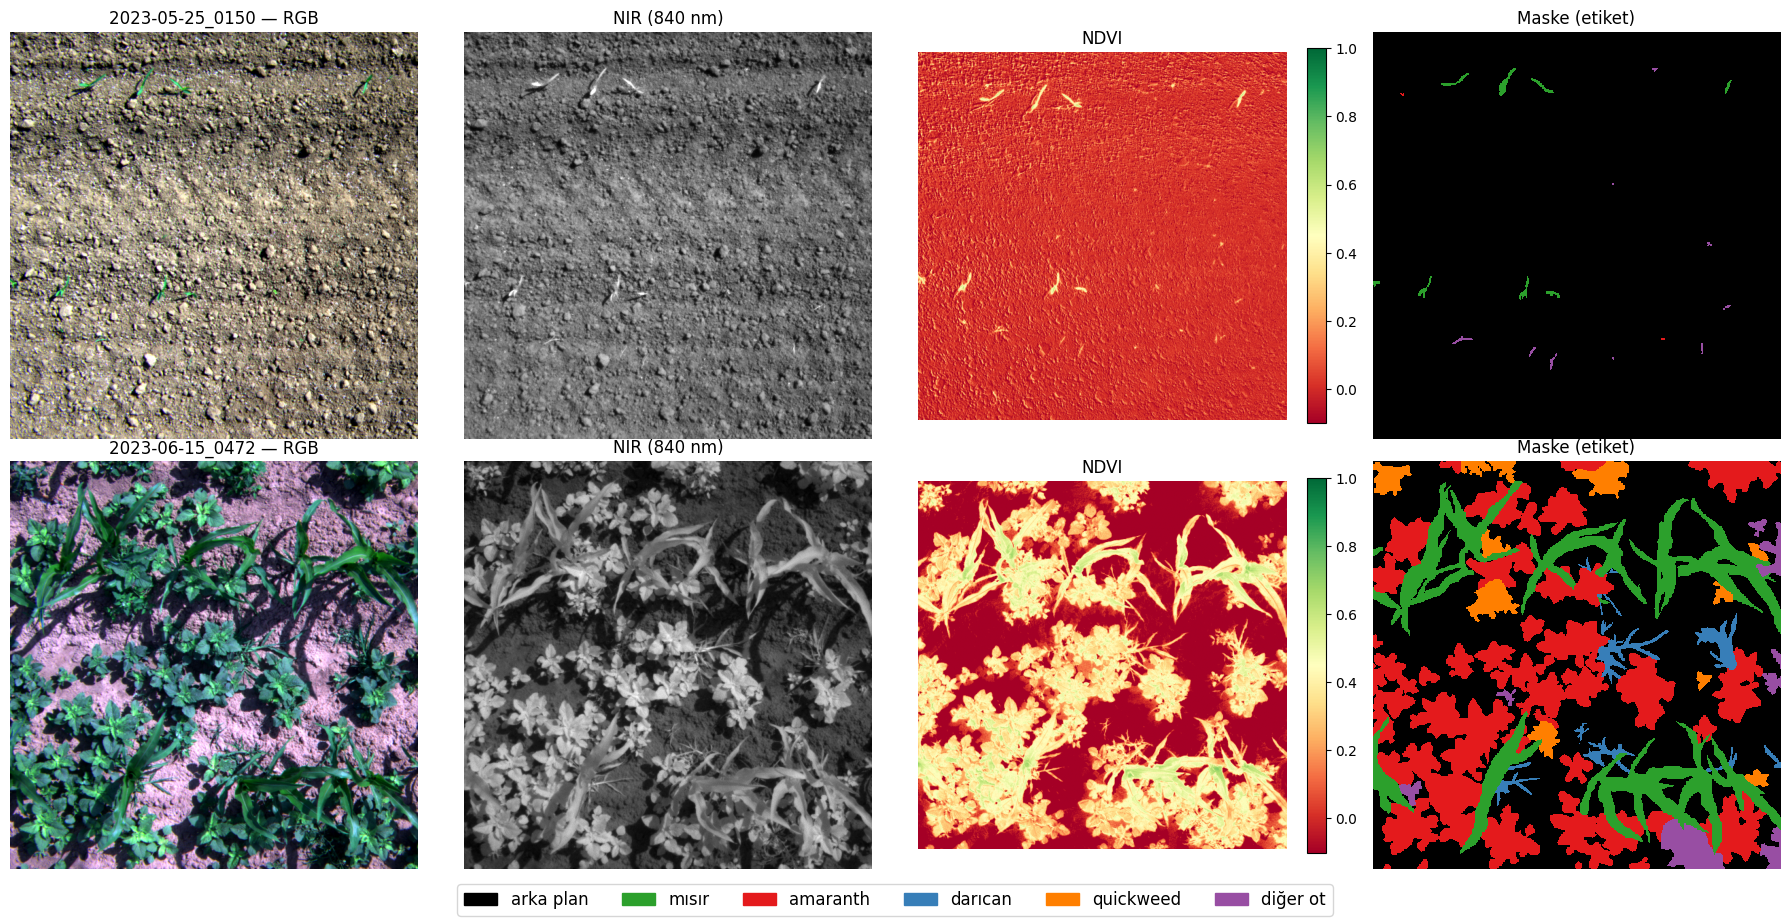

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

SINIFLAR = ['arka plan', 'mısır', 'amaranth', 'darıcan', 'quickweed', 'diğer ot']
RENKLER  = ['#000000', '#2ca02c', '#e41a1c', '#377eb8', '#ff7f00', '#984ea3']
CMAP = ListedColormap(RENKLER)

def bant_oku(ad):
    """5 bandı (B, G, R, RE, NIR sırasıyla) okur, 0–1 aralığında float32 (5, 600, 600) döndürür."""
    return np.stack([np.array(Image.open(f'{DATASET}/{ad[:10]}/images/{ad}_{b}.png'), dtype=np.float32) / 65535
                     for b in BANDS])

def maske_oku(ad):
    """Semantik maskeyi (600, 600) sınıf numaraları olarak okur."""
    return np.array(Image.open(f'{DATASET}/{ad[:10]}/semantics/{ad}.png'))

def gorunur_rgb(x):
    """R, G, B bantlarını ekranda görülebilir hale getirir (%1–%99 aralığına germe)."""
    rgb = np.stack([x[2], x[1], x[0]], axis=-1)
    lo, hi = np.percentile(rgb, [1, 99])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

# En erken ve en geç tarihten birer eğitim görüntüsü
ornekler = [next(a for a in splits['train'] if a.startswith('2023-05-25')),
            next(a for a in splits['train'] if a.startswith('2023-06-15'))]

fig, axes = plt.subplots(len(ornekler), 4, figsize=(18, 4.6 * len(ornekler)))
for i, ad in enumerate(ornekler):
    x, m = bant_oku(ad), maske_oku(ad)
    ndvi = (x[4] - x[2]) / (x[4] + x[2] + 1e-6)

    axes[i, 0].imshow(gorunur_rgb(x));                   axes[i, 0].set_title(f'{ad} — RGB')
    axes[i, 1].imshow(x[4], cmap='gray');                axes[i, 1].set_title('NIR (840 nm)')
    im = axes[i, 2].imshow(ndvi, cmap='RdYlGn', vmin=-0.1, vmax=1); axes[i, 2].set_title('NDVI')
    fig.colorbar(im, ax=axes[i, 2], fraction=0.046)
    axes[i, 3].imshow(m, cmap=CMAP, vmin=-0.5, vmax=5.5, interpolation='nearest')
    axes[i, 3].set_title('Maske (etiket)')
    for ax in axes[i]: ax.axis('off')

fig.legend(handles=[Patch(color=r, label=s) for r, s in zip(RENKLER, SINIFLAR)],
           loc='lower center', ncol=6, fontsize=12)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f'{RES_DIR}/eda_01_ornekler.png', dpi=150)
plt.show()

## 4. Bant değerleri ve normalizasyon

bant  ortalama   std  görüntü max (en düşük)  görüntü max (medyan)
   B     0.408 0.114                   0.990                 0.995
   G     0.444 0.117                   0.969                 0.986
   R     0.463 0.125                   0.933                 0.984
  RE     0.433 0.108                   0.901                 0.984
 NIR     0.408 0.106                   0.863                 0.981

Tüm değerler 64'ün katı mı? True


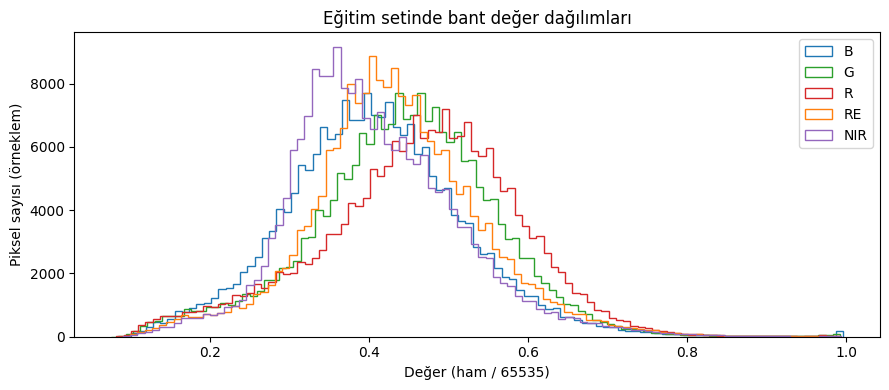

In [ ]:
import pandas as pd

toplam, kare_toplam, piksel = np.zeros(5), np.zeros(5), 0
goruntu_max = []
kat64 = True
orneklem = [[] for _ in BANDS]
rng = np.random.default_rng(SEED)

for ad in splits['train']:          # sadece eğitim seti: val/test istatistiği modele sızmasın
    ham = np.stack([np.array(Image.open(f'{DATASET}/{ad[:10]}/images/{ad}_{b}.png')) for b in BANDS])  # uint16
    kat64 &= bool((ham % 64 == 0).all())
    x = ham.astype(np.float64) / 65535
    toplam      += x.sum(axis=(1, 2))
    kare_toplam += (x ** 2).sum(axis=(1, 2))
    piksel      += x[0].size
    goruntu_max.append(x.max(axis=(1, 2)))
    idx = rng.choice(x[0].size, 2000, replace=False)
    for j in range(5):
        orneklem[j].append(x[j].ravel()[idx])

ort = toplam / piksel
std = np.sqrt(kare_toplam / piksel - ort ** 2)
goruntu_max = np.array(goruntu_max)

tablo = pd.DataFrame({'bant': BANDS,
                      'ortalama': ort, 'std': std,
                      'görüntü max (en düşük)': goruntu_max.min(0),
                      'görüntü max (medyan)': np.median(goruntu_max, 0)}).round(3)
print(tablo.to_string(index=False))
print("\nTüm değerler 64'ün katı mı?", kat64)

# Normalizasyon istatistiklerini kaydet: eğitimde (x - ort) / std için kullanılacak
np.save(f'{RES_DIR}/norm_ort.npy', ort.astype(np.float32))
np.save(f'{RES_DIR}/norm_std.npy', std.astype(np.float32))

# Bant başına değer dağılımı (histogram)
renk = ['tab:blue', 'tab:green', 'tab:red', 'tab:orange', 'tab:purple']
fig, ax = plt.subplots(figsize=(9, 4))
for j, b in enumerate(BANDS):
    ax.hist(np.concatenate(orneklem[j]), bins=100, histtype='step', lw=1.5, color=renk[j], label=b)
ax.set_xlabel('Değer (ham / 65535)')
ax.set_ylabel('Piksel sayısı (örneklem)')
ax.set_title('Eğitim setinde bant değer dağılımları')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RES_DIR}/eda_02_bant_histogram.png', dpi=150)
plt.show()

## 5. Sınıf dağılımı

Instance dosyası örneği: 2023-06-15_0472.png | dtype: uint8

Piksel oranı (%):
             train     val    test
arka plan  93.352  92.442  92.694
mısır       2.445   2.850   1.993
amaranth    2.715   3.491   3.557
darıcan     0.898   0.422   1.093
quickweed   0.181   0.378   0.102
diğer ot    0.409   0.417   0.560

Nesne sayısı:
            bizim sayım  makale
mısır             2168    2169
amaranth          4115    4109
darıcan           2535    2537
quickweed          247     249
diğer ot          3132    3136


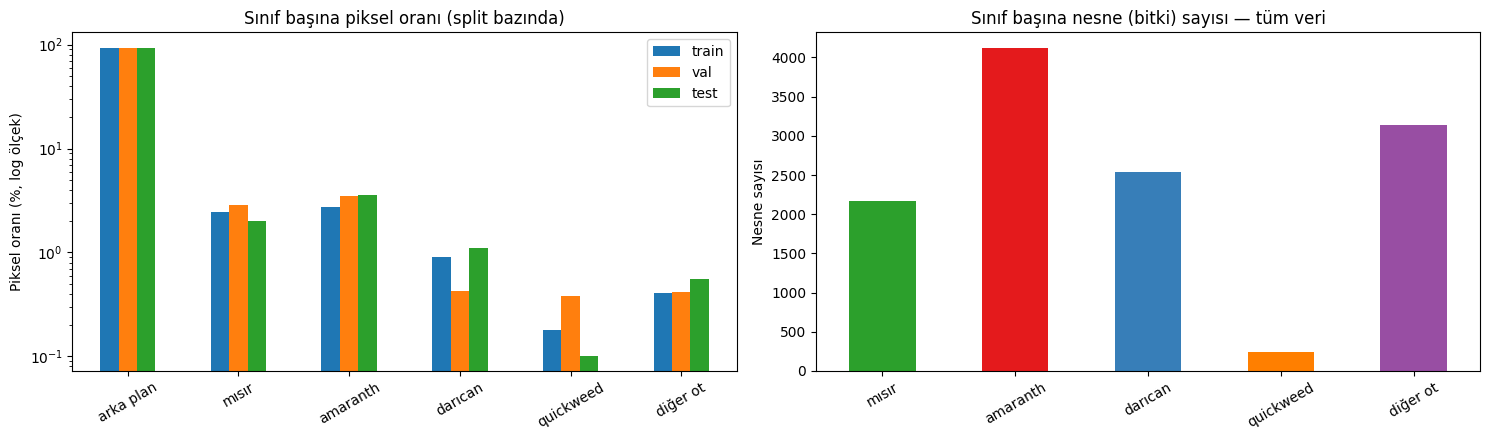

In [ ]:
piksel_say = {s: np.zeros(6, dtype=np.int64) for s in splits}
nesneler = []

ilk = glob.glob(f'{DATASET}/{splits["train"][0][:10]}/instances/{splits["train"][0]}*')[0]
print('Instance dosyası örneği:', os.path.basename(ilk), '| dtype:', np.array(Image.open(ilk)).dtype)

for s, adlar in splits.items():
    for ad in adlar:
        m = maske_oku(ad)
        piksel_say[s] += np.bincount(m.ravel(), minlength=6)

        # Instance maskesi: her nesnenin kendine ait bir kimlik (id) numarası var, 0 = nesne yok
        inst = np.array(Image.open(glob.glob(f'{DATASET}/{ad[:10]}/instances/{ad}*')[0]))
        if inst.ndim == 3:
            inst = inst[..., 0].astype(np.int64) * 65536 + inst[..., 1] * 256 + inst[..., 2]
        ids, sem = inst.ravel().astype(np.int64), m.ravel()
        nz = ids > 0
        anahtar, say = np.unique(ids[nz] * 6 + sem[nz], return_counts=True)
        nid, ncls = anahtar // 6, anahtar % 6
        for i in np.unique(nid):
            sec = nid == i
            nesneler.append((s, ad[:10], int(ncls[sec][np.argmax(say[sec])]), int(say[sec].sum())))
            # nesnenin sınıfı = piksellerinin çoğunluğunun sınıfı; alanı = toplam piksel

nesne_df = pd.DataFrame(nesneler, columns=['split', 'tarih', 'sinif', 'alan'])
nesne_df.to_csv(f'{RES_DIR}/nesneler.csv', index=False)

# --- Tablo 1: piksel oranı (%) ---
oran = pd.DataFrame({s: 100 * piksel_say[s] / piksel_say[s].sum() for s in splits}, index=SINIFLAR).round(3)
print('\nPiksel oranı (%):\n', oran.to_string())

# --- Tablo 2: nesne sayısı (makaleyle karşılaştırma) ---
makale = {'mısır': 2169, 'amaranth': 4109, 'darıcan': 2537, 'quickweed': 249, 'diğer ot': 3136}
say_tab = nesne_df[nesne_df.sinif > 0].groupby('sinif').size()
say_tab.index = [SINIFLAR[i] for i in say_tab.index]
print('\nNesne sayısı:\n', pd.DataFrame({'bizim sayım': say_tab, 'makale': pd.Series(makale)}).to_string())

# --- Görsel: piksel oranı (log ölçek) + nesne sayısı ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
oran.plot.bar(ax=axes[0], logy=True, rot=30)
axes[0].set_ylabel('Piksel oranı (%, log ölçek)')
axes[0].set_title('Sınıf başına piksel oranı (split bazında)')
say_tab.plot.bar(ax=axes[1], color=RENKLER[1:], rot=30)
axes[1].set_ylabel('Nesne sayısı')
axes[1].set_title('Sınıf başına nesne (bitki) sayısı — tüm veri')
plt.tight_layout()
plt.savefig(f'{RES_DIR}/eda_03_sinif_dagilimi.png', dpi=150)
plt.show()

## 6. Nesne boyutları ve GSD etkisi

Sınıf başına nesne boyutu:
            adet  medyan_piksel  medyan_cm2  medyan_cap_px
sinif_ad                                                 
mısır      2168          261.0        16.3           18.2
amaranth   4115          156.0         9.8           14.1
darıcan    2535           93.0         5.8           10.9
quickweed   247          276.0        17.2           18.7
diğer ot   3132           28.0         1.8            6.0

Tarih başına medyan alan (cm²):
 tarih      2023-05-25  2023-05-30  2023-06-06  2023-06-15
sinif_ad                                                 
mısır             8.8        20.2        46.5       135.2
amaranth          1.9         4.7        13.2        60.5
darıcan           1.8         3.3         6.2        27.8
quickweed         2.1         5.3        11.4        39.4
diğer ot          1.2         1.9         3.6        35.6

Çapı 3 pikselin altına düşen nesne (%):
            2.5 mm  5 mm  10 mm  20 mm
sinif_ad                             
mısır   

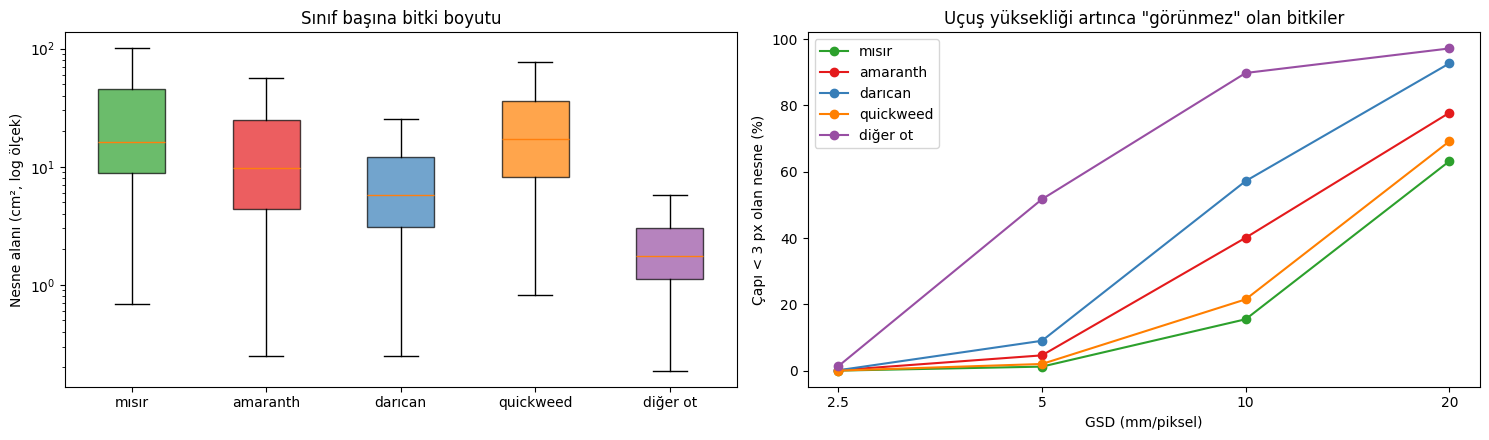

In [ ]:
GSD_MM = 2.5                                              # 5 m uçuşta 1 piksel = 2.5 mm
nesne_df['alan_cm2'] = nesne_df.alan * (GSD_MM / 10) ** 2
nesne_df['cap_px']   = 2 * np.sqrt(nesne_df.alan / np.pi) # aynı alandaki dairenin çapı (piksel)
bitki = nesne_df[nesne_df.sinif > 0].copy()
bitki['sinif_ad'] = bitki.sinif.map(lambda i: SINIFLAR[i])
SIRA = SINIFLAR[1:]

# Tablo 1: sınıf başına boyut özeti
ozet = bitki.groupby('sinif_ad').agg(adet=('alan', 'size'),
                                     medyan_piksel=('alan', 'median'),
                                     medyan_cm2=('alan_cm2', 'median'),
                                     medyan_cap_px=('cap_px', 'median')).reindex(SIRA).round(1)
print('Sınıf başına nesne boyutu:\n', ozet.to_string())

# Tablo 2: tarih başına medyan alan (cm²) - bitkiler ne kadar büyüyor?
tarih_tab = bitki.pivot_table(index='sinif_ad', columns='tarih', values='alan_cm2',
                              aggfunc='median').reindex(SIRA).round(1)
print('\nTarih başına medyan alan (cm²):\n', tarih_tab.to_string())

# Tablo 3: uçuş yüksekliği artarsa (GSD büyürse) çapı 3 pikselin altına düşen nesne yüzdesi
ESIK_PX = 3                                               # ~3 pikselden küçük nesne pratikte görünmez
GSDLER = [2.5, 5, 10, 20]                                 # mm/piksel (yaklaşık 5 / 10 / 20 / 40 m uçuş)
gsd_tab = pd.DataFrame({f'{g} mm': bitki.groupby('sinif_ad').cap_px
                                      .apply(lambda c: 100 * (c * GSD_MM / g < ESIK_PX).mean())
                        for g in GSDLER}).reindex(SIRA).round(1)
print(f'\nÇapı {ESIK_PX} pikselin altına düşen nesne (%):\n', gsd_tab.to_string())

# Görsel: (a) alan dağılımı kutu grafiği, (b) GSD'ye göre kaybolan nesne oranı
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
kutu = axes[0].boxplot([bitki[bitki.sinif_ad == s].alan_cm2 for s in SIRA],
                       tick_labels=SIRA, patch_artist=True, showfliers=False)
for p, r in zip(kutu['boxes'], RENKLER[1:]):
    p.set_facecolor(r); p.set_alpha(0.7)
axes[0].set_yscale('log')
axes[0].set_ylabel('Nesne alanı (cm², log ölçek)')
axes[0].set_title('Sınıf başına bitki boyutu')
for s, r in zip(SIRA, RENKLER[1:]):
    axes[1].plot(GSDLER, gsd_tab.loc[s].values, marker='o', color=r, label=s)
axes[1].set_xscale('log', base=2); axes[1].set_xticks(GSDLER, [str(g) for g in GSDLER])
axes[1].set_xlabel('GSD (mm/piksel)')
axes[1].set_ylabel(f'Çapı < {ESIK_PX} px olan nesne (%)')
axes[1].set_title('Uçuş yüksekliği artınca "görünmez" olan bitkiler')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{RES_DIR}/eda_04_nesne_boyutu.png', dpi=150)
plt.show()

## 7. Sınıflara göre bant ve indeks değerleri

Örneklenen piksel sayısı (sınıf başına): [312000, 285416, 169580, 120724, 37549, 107477]

Ayrışma gücü |d| (büyük = iyi ayırıyor):
       toprak ↔ bitki  mısır ↔ tüm otlar  amaranth ↔ quickweed
B               0.68               0.14                  0.03
G               0.03               0.50                  0.13
R               1.40               0.15                  0.42
RE              1.22               0.38                  0.21
NIR             1.50               0.49                  0.25
NDVI            2.59               0.49                  0.15
ExG             1.46               0.81                  0.12


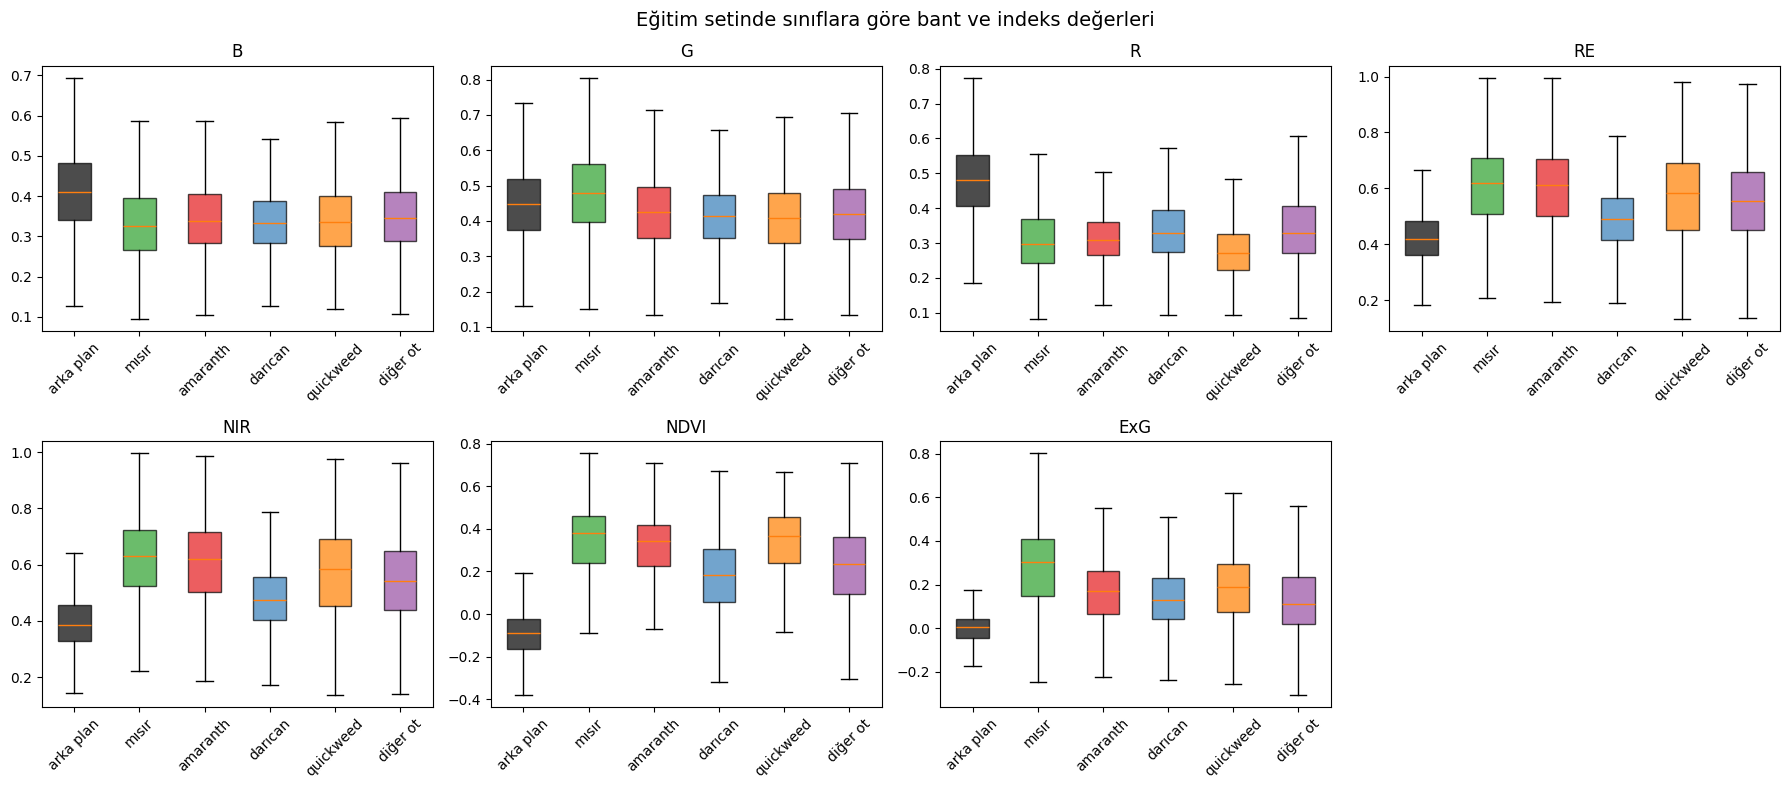

In [ ]:
rng = np.random.default_rng(SEED)
N_MAX = 3000          # görüntü başına, sınıf başına en fazla bu kadar piksel örnekle
OZELLIK = BANDS + ['NDVI', 'ExG']
parcalar = []

for ad in splits['train']:
    X = bant_oku(ad).reshape(5, -1)
    m = maske_oku(ad).ravel()
    B, G, R, RE, NIR = X
    ndvi = (NIR - R) / (NIR + R + 1e-6)              # NIR gerektirir -> yalnız multispektral kamera
    toplam = B + G + R + 1e-6
    exg = (2 * G - R - B) / toplam                   # Excess Green: yalnız RGB'den hesaplanır
    for c in range(6):
        idx = np.flatnonzero(m == c)
        if len(idx) == 0:
            continue
        idx = rng.choice(idx, min(len(idx), N_MAX), replace=False)
        parcalar.append(np.column_stack([np.full(len(idx), c), X[:, idx].T, ndvi[idx], exg[idx]]))

P = pd.DataFrame(np.concatenate(parcalar), columns=['sinif'] + OZELLIK)
P['sinif'] = P.sinif.astype(int)
print('Örneklenen piksel sayısı (sınıf başına):', P.sinif.value_counts().sort_index().tolist())

# Ayrışma gücü: iki grubun ortalama farkı / ortak std (Cohen's d). |d| > 0.8 "büyük" ayrışma.
def cohen_d(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

ciftler = {'toprak ↔ bitki':     (P.sinif == 0, P.sinif > 0),
           'mısır ↔ tüm otlar':   (P.sinif == 1, P.sinif > 1),
           'amaranth ↔ quickweed': (P.sinif == 2, P.sinif == 4)}
d_tab = pd.DataFrame({ad: [abs(cohen_d(P.loc[a, f], P.loc[b, f])) for f in OZELLIK]
                      for ad, (a, b) in ciftler.items()}, index=OZELLIK).round(2)
print('\nAyrışma gücü |d| (büyük = iyi ayırıyor):\n', d_tab.to_string())

# Görsel: her özellik için sınıf bazında kutu grafiği
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), OZELLIK):
    kutu = ax.boxplot([P.loc[P.sinif == c, f] for c in range(6)], patch_artist=True,
                      showfliers=False, tick_labels=SINIFLAR)
    for p, r in zip(kutu['boxes'], RENKLER):
        p.set_facecolor(r); p.set_alpha(0.7)
    ax.set_title(f); ax.tick_params(axis='x', rotation=45)
axes.ravel()[-1].axis('off')
plt.suptitle('Eğitim setinde sınıflara göre bant ve indeks değerleri', fontsize=14)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/eda_05_sinif_bant.png', dpi=150)
plt.show()

## 8. Tarihe göre değişim

Tarih başına piksel oranı (%):
             arka plan  mısır  amaranth  darıcan  quickweed  diğer ot  bitki örtüsü  ot / mısır
2023-05-25      99.08   0.67      0.03     0.02       0.00      0.19          0.92        0.36
2023-05-30      97.89   1.16      0.59     0.15       0.01      0.20          2.11        0.82
2023-06-06      91.12   3.36      3.56     1.32       0.17      0.47          8.88        1.65
2023-06-15      57.82  10.91     22.05     5.10       1.88      2.23         42.18        2.86

Mısır ↔ ot ayrışması |d|, tarih bazında:
              ExG     G  NDVI   NIR
2023-05-25  1.27  0.50  1.14  0.70
2023-05-30  1.03  0.34  0.53  0.15
2023-06-06  1.15  0.77  0.41  0.37
2023-06-15  0.57  0.13  0.59  0.18


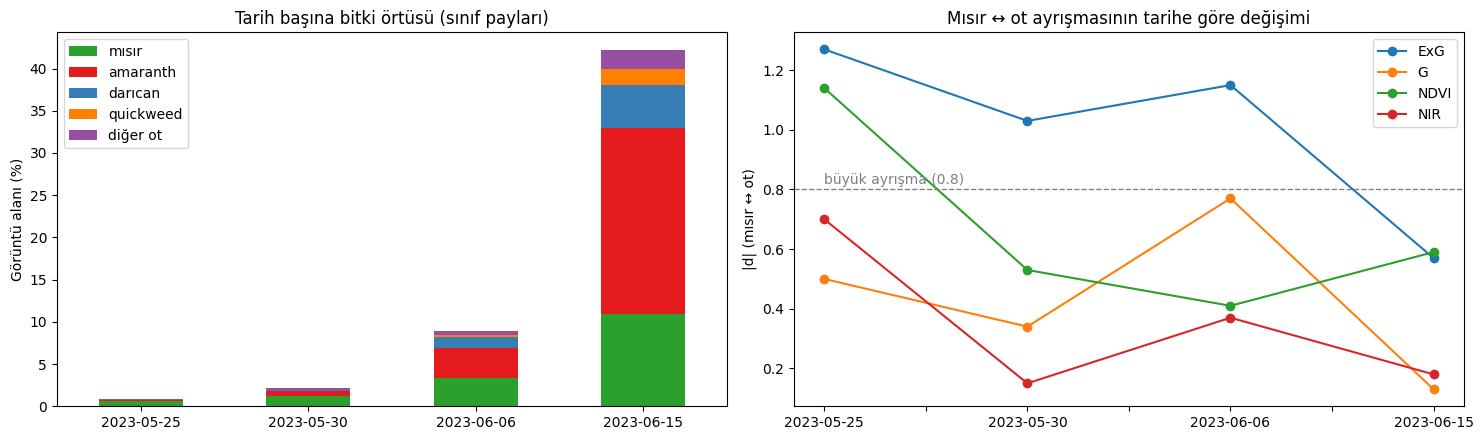

In [ ]:
# (a) Tarih başına sınıf piksel oranı - tüm 156 görüntü (betimsel bilgi, model kararı değil)
tarih_piksel = {d: np.zeros(6, dtype=np.int64) for d in DATES}
for ad in tum:
    tarih_piksel[ad[:10]] += np.bincount(maske_oku(ad).ravel(), minlength=6)
tp = pd.DataFrame(tarih_piksel, index=SINIFLAR).T
tp_oran = 100 * tp.div(tp.sum(axis=1), axis=0)
tp_oran['bitki örtüsü'] = 100 - tp_oran['arka plan']
tp_oran['ot / mısır'] = tp_oran[SINIFLAR[2:]].sum(axis=1) / tp_oran['mısır']   # mısır başına ot pikseli
print('Tarih başına piksel oranı (%):\n', tp_oran.round(2).to_string())

# (b) Mısır ↔ ot ayrışması (|d|) tarihe göre değişiyor mu? - yalnız train
rng = np.random.default_rng(SEED)
satirlar = []
for ad in splits['train']:
    X = bant_oku(ad).reshape(5, -1); m = maske_oku(ad).ravel()
    B, G, R, RE, NIR = X
    ndvi = (NIR - R) / (NIR + R + 1e-6)
    exg  = (2 * G - R - B) / (B + G + R + 1e-6)
    for grup, secim in [('mısır', m == 1), ('ot', m > 1)]:
        idx = np.flatnonzero(secim)
        if len(idx) == 0:
            continue
        idx = rng.choice(idx, min(len(idx), 3000), replace=False)
        satirlar.append(pd.DataFrame({'tarih': ad[:10], 'grup': grup,
                                      'NDVI': ndvi[idx], 'ExG': exg[idx], 'NIR': NIR[idx], 'G': G[idx]}))
T = pd.concat(satirlar)
d_tarih = pd.DataFrame({f: [abs(cohen_d(T[(T.tarih == d) & (T.grup == 'mısır')][f],
                                        T[(T.tarih == d) & (T.grup == 'ot')][f])) for d in DATES]
                        for f in ['ExG', 'G', 'NDVI', 'NIR']}, index=DATES).round(2)
print('\nMısır ↔ ot ayrışması |d|, tarih bazında:\n', d_tarih.to_string())

# Görsel
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tp_oran[SINIFLAR[1:]].plot.bar(stacked=True, color=RENKLER[1:], ax=axes[0], rot=0)
axes[0].set_ylabel('Görüntü alanı (%)')
axes[0].set_title('Tarih başına bitki örtüsü (sınıf payları)')
d_tarih.plot(marker='o', ax=axes[1], rot=0)
axes[1].axhline(0.8, ls='--', c='gray', lw=1); axes[1].text(0, 0.82, 'büyük ayrışma (0.8)', color='gray')
axes[1].set_ylabel('|d| (mısır ↔ ot)')
axes[1].set_title('Mısır ↔ ot ayrışmasının tarihe göre değişimi')
plt.tight_layout()
plt.savefig(f'{RES_DIR}/eda_06_tarih.png', dpi=150)
plt.show()